<a href="https://colab.research.google.com/github/QHIZER/BIS-LAB/blob/main/Parallel_Cellular_Algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best Solution: 2.0
Best Fitness: 0.0


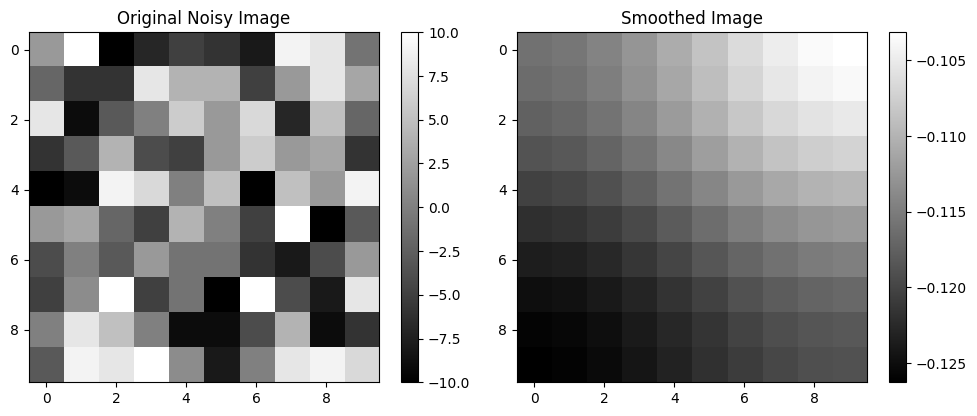

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# Fitness Function
def Fitness(x):
    return x*x - 4*x + 4


# Initialize the grid
def Initialize():
    grid = np.random.randint(-10, 11, (10, 10))
    return grid.astype(float)


# Update cell states using neighbourhood average
def UpdateStates(grid):

    new_grid = np.zeros((10, 10))

    for i in range(10):
        for j in range(10):

            neighbours = []

            # Find 3x3 neighbourhood
            for x in range(max(0, i-1), min(10, i+2)):
                for y in range(max(0, j-1), min(10, j+2)):
                    neighbours.append(grid[x][y])

            # Calculate average
            new_grid[i][j] = np.mean(neighbours)

    return new_grid


# Main Program
def main():

    number_of_cells = 100
    max_iterations = 100

    # Initialize grid
    grid = Initialize()

    best_fitness = float('inf')
    best_solution = 0

    # Store initial grid
    initial_grid = grid.copy()

    # Iteration process
    for iteration in range(max_iterations):

        # Evaluate fitness of each cell
        for i in range(10):
            for j in range(10):

                x = grid[i][j]
                fitness = Fitness(x)

                if fitness < best_fitness:
                    best_fitness = fitness
                    best_solution = x

        # Update all cell states
        grid = UpdateStates(grid)

    # Display results
    print("Best Solution:", best_solution)
    print("Best Fitness:", best_fitness)

    # Display original and processed grids
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(initial_grid, cmap='gray')
    plt.title("Original Noisy Image")
    plt.colorbar()

    plt.subplot(1, 2, 2)
    plt.imshow(grid, cmap='gray')
    plt.title("Smoothed Image")
    plt.colorbar()

    plt.tight_layout()
    plt.show()


# Execute program
if __name__ == "__main__":
    main()
